In [1]:
"""
Soft-Vote Ensemble (SVM + XGBoost + LightGBM + LogReg + RF + ExtraTrees +
                    CatBoost + GradientBoosting + MLP-DL) — SFS Loop  [v3]
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Upgrades over v2
────────────────
  [13] RandomForestClassifier    — strong tree ensemble, low-variance OOF
  [14] ExtraTreesClassifier      — extremely randomised trees, fast + diverse
  [15] CatBoostClassifier        — gradient boosting w/ ordered boosting,
                                   handles class imbalance natively
  [16] GradientBoostingClassifier— sklearn GB, accurate on small datasets
  [17] MLP Deep-Learning model   — 3-layer MLP (PyTorch) with BatchNorm,
                                   Dropout, early stopping on val AUC;
                                   ideal for high-dim tabular gene expression
  [18] Dynamic weight vector     — WEIGHTS list now matches n_models exactly
  [19] Dynamic COLS              — per-model AUC columns auto-generated
  [20] Graceful DL fallback      — if torch unavailable, MLP is skipped &
                                   a warning is logged (no crash)

Deep-learning rationale for binary gene-expression classification
─────────────────────────────────────────────────────────────────
  • MLP (multi-layer perceptron) outperforms 1-D CNN on flat tabular
    features when there is no local structure (genes are unordered here).
  • BatchNorm + Dropout prevents overfitting on the small GEO dataset.
  • Class-weighted BCE loss handles imbalance without SMOTE leakage.
  • Training on SMOTE-augmented data mirrors the other models for
    consistency; early stopping on a clean (pre-SMOTE) val set avoids
    overfitting.
"""
from __future__ import annotations

import logging
import os
import random
import warnings
from dataclasses import dataclass, field

import lightgbm as lgb
import mygene
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE
from lightgbm import LGBMClassifier
from sklearn.ensemble import (
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from tqdm import tqdm
from xgboost import XGBClassifier

# ── Optional deep-learning (PyTorch) ────────────────────────────────────────
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, TensorDataset
    TORCH_OK = True
except ImportError:
    TORCH_OK = False

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)



In [2]:

# ══════════════════════════════════════════════════════════
# [1] CONFIG
# ══════════════════════════════════════════════════════════
@dataclass
class Config:
    seed: int = 42
    n_splits: int = 5
    sfs_start: int = 10        # inclusive; SFS begins at feature index 10
    n_features: int = 208      # total features in ranked pool
    smote_k: int = 3

    # ── SVM ───────────────────────────────────────────────
    svm_C: float = 1.0
    svm_gamma: str = "scale"

    # ── XGBoost ──────────────────────────────────────────
    xgb_n_est: int = 300
    xgb_depth: int = 4
    xgb_lr: float = 0.05
    xgb_early_stop: int = 20

    # ── LightGBM ─────────────────────────────────────────
    lgbm_n_est: int = 300
    lgbm_depth: int = 4
    lgbm_lr: float = 0.05
    lgbm_early_stop: int = 20

    # ── LogisticRegression ───────────────────────────────
    lr_C: float = 1.0
    lr_max_iter: int = 2000

    # ── [13] RandomForest ────────────────────────────────
    rf_n_est: int = 300
    rf_depth: int | None = None   # None = unlimited
    rf_min_leaf: int = 1

    # ── [14] ExtraTrees ──────────────────────────────────
    et_n_est: int = 300
    et_depth: int | None = None

    # ── [15] CatBoost ────────────────────────────────────
    cb_iterations: int = 300
    cb_depth: int = 4
    cb_lr: float = 0.05
    cb_early_stop: int = 20

    # ── [16] GradientBoosting ────────────────────────────
    gb_n_est: int = 200
    gb_depth: int = 3
    gb_lr: float = 0.05

    # ── [17] MLP Deep Learning ───────────────────────────
    dl_hidden: tuple = (256, 128, 64)   # layer widths
    dl_dropout: float = 0.3
    dl_lr: float = 1e-3
    dl_epochs: int = 150
    dl_batch: int = 32
    dl_early_stop: int = 15             # patience (val AUC)
    dl_weight_decay: float = 1e-4

    # ── [18] Soft-vote weights (auto-normalised)
    #        Order: SVM, XGB, LGBM, LR, RF, ET, CB, GB, MLP
    w_svm:  float = 1.0
    w_xgb:  float = 1.0
    w_lgbm: float = 1.0
    w_lr:   float = 1.0
    w_rf:   float = 1.0
    w_et:   float = 1.0
    w_cb:   float = 1.0
    w_gb:   float = 1.0
    w_mlp:  float = 1.0   # ignored automatically if torch unavailable

    # ── Paths ─────────────────────────────────────────────
    data_dir: str = (
        r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\backup1\python_desque2_lung\Binary\data\ranked rf"
    )
    out_dir: str = (
        r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\backup1\python_desque2_lung\Binary\data\sfs"
    )
    train_csv: str = "VotingClassifier_v3_train.csv"
    test_csv: str  = "VotingClassifier_v3_test.csv"


CFG = Config()



In [3]:

# ══════════════════════════════════════════════════════════
# [2] UTILITIES
# ══════════════════════════════════════════════════════════
def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    if TORCH_OK:
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)


def setup_logging() -> logging.Logger:
    logging.basicConfig(
        level=logging.INFO,
        format="%(asctime)s [%(levelname)s] %(message)s",
        datefmt="%H:%M:%S",
    )
    return logging.getLogger(__name__)


seed_everything(CFG.seed)
log = setup_logging()
os.makedirs(CFG.out_dir, exist_ok=True)

# ── Device for MLP ─────────────────────────────────────────────────────────
DEVICE = torch.device("cuda" if (TORCH_OK and torch.cuda.is_available()) else "cpu") if TORCH_OK else None
if TORCH_OK:
    log.info(f"PyTorch available — MLP will run on: {DEVICE}")
else:
    log.warning("PyTorch not found — MLP (deep-learning) model will be skipped.")



18:43:37 [INFO] PyTorch available — MLP will run on: cpu


In [4]:

# ══════════════════════════════════════════════════════════
# LOAD DATA + ENSEMBL → SYMBOL
# ══════════════════════════════════════════════════════════
X_train = pd.read_csv(os.path.join(CFG.data_dir, "X_train_rF_DEG_train_lung.csv"), low_memory=False)
X_test  = pd.read_csv(os.path.join(CFG.data_dir, "X_test_rF_DEG_train_lung.csv"),  low_memory=False)
y_train = pd.read_csv(os.path.join(CFG.data_dir, "y_train_rF_DEG_train.csv"), low_memory=False)
y_test  = pd.read_csv(os.path.join(CFG.data_dir, "y_test_rF_DEG_train.csv"),  low_memory=False)

ensembl_ids = [c for c in X_train.columns if c.startswith("ENSG")]
log.info(f"Querying MyGene.info for {len(ensembl_ids)} IDs…")
mg      = mygene.MyGeneInfo()
results = mg.querymany(ensembl_ids, scopes="ensembl.gene", fields="symbol", species="human")
id_map  = {r["query"]: r.get("symbol", r["query"]) for r in results}
X_train.rename(columns=id_map, inplace=True)
X_test.rename(columns=id_map, inplace=True)
X_train = X_train.iloc[:, :CFG.n_features]
X_test  = X_test.iloc[:, :CFG.n_features]
log.info("Gene symbol conversion complete.")

# ── Scale ──────────────────────────────────────────────────────────────────
scaler     = StandardScaler()
x_train_sc = scaler.fit_transform(X_train)
x_test_sc  = scaler.transform(X_test)

list_feature = list(X_train.columns)
ranks  = [[list_feature[j] for j in range(i + 1)] for i in range(len(list_feature))]
y_tr_all = y_train["cancer_type"].values
y_te_all = y_test["cancer_type"].values
ratio    = float((y_tr_all == 0).sum() / (y_tr_all == 1).sum())
skf      = StratifiedKFold(n_splits=CFG.n_splits, shuffle=True, random_state=CFG.seed)

# ── [18] Build dynamic weight list ─────────────────────────────────────────
BASE_WEIGHTS_ALL = [
    CFG.w_svm, CFG.w_xgb, CFG.w_lgbm, CFG.w_lr,
    CFG.w_rf,  CFG.w_et,  CFG.w_cb,   CFG.w_gb,
    CFG.w_mlp,
]
MODEL_NAMES_ALL = ["SVM", "XGB", "LGBM", "LR", "RF", "ET", "CB", "GB", "MLP"]

# Drop MLP if torch not available
if not TORCH_OK:
    BASE_WEIGHTS_ALL = BASE_WEIGHTS_ALL[:-1]
    MODEL_NAMES_ALL  = MODEL_NAMES_ALL[:-1]

WEIGHTS     = BASE_WEIGHTS_ALL          # normalised inside soft_vote()
MODEL_NAMES = MODEL_NAMES_ALL



18:43:37 [INFO] Querying MyGene.info for 211 IDs…
18:43:37 [INFO] querying 1-211 ...
18:43:39 [INFO] HTTP Request: POST https://mygene.info/v3/query/ "HTTP/1.1 200 OK"
18:43:40 [INFO] Finished.
18:43:40 [WARNING] 5 input query terms found no hit:	['ENSG00000197459', 'ENSG00000267243', 'ENSG00000136653', 'ENSG00000163386', 'ENSG00000148362']
18:43:40 [INFO] Pass "returnall=True" to return complete lists of duplicate or missing query terms.
18:43:40 [INFO] Gene symbol conversion complete.


In [5]:

# ══════════════════════════════════════════════════════════
# METRICS
# ══════════════════════════════════════════════════════════
def cfm(y_true: np.ndarray, y_pred: np.ndarray, y_prob: np.ndarray) -> np.ndarray:
    auc = roc_auc_score(y_true, y_prob)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    acc  = accuracy_score(y_true, y_pred)
    rec  = tp / (tp + fn)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    spec = tn / (tn + fp)
    f1   = (2 * rec * prec) / (rec + prec) if (rec + prec) > 0 else 0.0
    # returns [acc, recall, precision, specificity, sensitivity, f1, auc]
    return np.array([acc, rec, prec, spec, rec, f1, auc])



In [6]:

# ══════════════════════════════════════════════════════════
# [6] SMOTE SPLIT HELPER
# ══════════════════════════════════════════════════════════
def _smote_split(X: np.ndarray, y: np.ndarray, val_frac: float = 0.15):
    """
    1. Split original data → train_s / val  (no synthetic samples in val)
    2. Apply SMOTE only to train_s
    Returns: X_sm, y_sm, X_val, y_val
    """
    X_s, X_v, y_s, y_v = train_test_split(
        X, y, test_size=val_frac, stratify=y, random_state=CFG.seed
    )
    X_sm, y_sm = SMOTE(k_neighbors=CFG.smote_k, random_state=CFG.seed).fit_resample(X_s, y_s)
    return X_sm, y_sm, X_v, y_v



In [7]:

# ══════════════════════════════════════════════════════════
# MODEL FACTORIES
# ══════════════════════════════════════════════════════════

# ── Original models (v2) ────────────────────────────────────────────────────
def fit_svm(X: np.ndarray, y: np.ndarray) -> SVC:
    X_sm, y_sm = SMOTE(k_neighbors=CFG.smote_k, random_state=CFG.seed).fit_resample(X, y)
    m = SVC(
        kernel="rbf", C=CFG.svm_C, gamma=CFG.svm_gamma,
        class_weight="balanced", probability=True, random_state=CFG.seed,
    )
    m.fit(X_sm, y_sm)
    return m


def fit_xgb(X: np.ndarray, y: np.ndarray) -> XGBClassifier:
    X_sm, y_sm, X_v, y_v = _smote_split(X, y)
    m = XGBClassifier(
        n_estimators=CFG.xgb_n_est, max_depth=CFG.xgb_depth, learning_rate=CFG.xgb_lr,
        scale_pos_weight=ratio, eval_metric="logloss",
        early_stopping_rounds=CFG.xgb_early_stop,
        random_state=CFG.seed, n_jobs=-1,
    )
    m.fit(X_sm, y_sm, eval_set=[(X_v, y_v)], verbose=False)
    return m


def fit_lgbm(X: np.ndarray, y: np.ndarray) -> LGBMClassifier:
    X_sm, y_sm, X_v, y_v = _smote_split(X, y)
    m = LGBMClassifier(
        n_estimators=CFG.lgbm_n_est, max_depth=CFG.lgbm_depth, learning_rate=CFG.lgbm_lr,
        is_unbalance=True, random_state=CFG.seed, n_jobs=-1, verbose=-1,
    )
    m.fit(
        X_sm, y_sm, eval_set=[(X_v, y_v)],
        callbacks=[
            lgb.early_stopping(CFG.lgbm_early_stop, verbose=False),
            lgb.log_evaluation(-1),
        ],
    )
    return m


def fit_lr(X: np.ndarray, y: np.ndarray) -> LogisticRegression:
    X_sm, y_sm = SMOTE(k_neighbors=CFG.smote_k, random_state=CFG.seed).fit_resample(X, y)
    m = LogisticRegression(
        solver="liblinear", penalty="l2", C=CFG.lr_C,
        class_weight="balanced", max_iter=CFG.lr_max_iter, random_state=CFG.seed,
    )
    m.fit(X_sm, y_sm)
    return m


# ── [13] Random Forest ──────────────────────────────────────────────────────
def fit_rf(X: np.ndarray, y: np.ndarray) -> RandomForestClassifier:
    """
    Random Forest with SMOTE augmentation and class balancing.
    Strong baseline; low variance thanks to averaging many deep trees.
    """
    X_sm, y_sm = SMOTE(k_neighbors=CFG.smote_k, random_state=CFG.seed).fit_resample(X, y)
    m = RandomForestClassifier(
        n_estimators=CFG.rf_n_est,
        max_depth=CFG.rf_depth,
        min_samples_leaf=CFG.rf_min_leaf,
        class_weight="balanced",
        random_state=CFG.seed,
        n_jobs=-1,
    )
    m.fit(X_sm, y_sm)
    return m


# ── [14] Extra Trees ────────────────────────────────────────────────────────
def fit_et(X: np.ndarray, y: np.ndarray) -> ExtraTreesClassifier:
    """
    Extremely Randomised Trees — faster than RF, adds diversity to ensemble.
    Particularly effective on high-dimensional gene expression data.
    """
    X_sm, y_sm = SMOTE(k_neighbors=CFG.smote_k, random_state=CFG.seed).fit_resample(X, y)
    m = ExtraTreesClassifier(
        n_estimators=CFG.et_n_est,
        max_depth=CFG.et_depth,
        class_weight="balanced",
        random_state=CFG.seed,
        n_jobs=-1,
    )
    m.fit(X_sm, y_sm)
    return m


# ── [15] CatBoost ───────────────────────────────────────────────────────────
def fit_cb(X: np.ndarray, y: np.ndarray) -> CatBoostClassifier:
    """
    CatBoost with ordered boosting — handles small/imbalanced datasets well.
    Uses auto_class_weights instead of SMOTE to stay compatible with its
    internal eval pool (SMOTE augmented data can confuse CatBoost's border
    computation).
    """
    X_s, X_v, y_s, y_v = train_test_split(
        X, y, test_size=0.15, stratify=y, random_state=CFG.seed
    )
    m = CatBoostClassifier(
        iterations=CFG.cb_iterations,
        depth=CFG.cb_depth,
        learning_rate=CFG.cb_lr,
        auto_class_weights="Balanced",
        eval_metric="AUC",
        early_stopping_rounds=CFG.cb_early_stop,
        random_seed=CFG.seed,
        verbose=False,
        thread_count=-1,
    )
    m.fit(X_s, y_s, eval_set=(X_v, y_v))
    return m


# ── [16] Gradient Boosting ──────────────────────────────────────────────────
def fit_gb(X: np.ndarray, y: np.ndarray) -> GradientBoostingClassifier:
    """
    Sklearn GradientBoosting — sequential, low-bias; works well on small
    biomedical datasets; no native early stopping → fixed n_estimators.
    SMOTE on full training fold.
    """
    X_sm, y_sm = SMOTE(k_neighbors=CFG.smote_k, random_state=CFG.seed).fit_resample(X, y)
    m = GradientBoostingClassifier(
        n_estimators=CFG.gb_n_est,
        max_depth=CFG.gb_depth,
        learning_rate=CFG.gb_lr,
        random_state=CFG.seed,
    )
    m.fit(X_sm, y_sm)
    return m


# ══════════════════════════════════════════════════════════
# [17] MLP DEEP-LEARNING MODEL (PyTorch)
# ══════════════════════════════════════════════════════════
if TORCH_OK:
    class _MLP(nn.Module):
        """
        3-layer MLP with BatchNorm + Dropout for binary gene-expression
        classification.  Architecture: Input → FC → BN → ReLU → Drop →
                                        FC → BN → ReLU → Drop →
                                        FC → BN → ReLU → Drop →
                                        FC(1) → Sigmoid
        BatchNorm stabilises training when feature counts vary across SFS
        steps. Dropout prevents overfitting on the small GEO sample.
        """
        def __init__(self, in_dim: int, hidden: tuple, dropout: float):
            super().__init__()
            layers: list[nn.Module] = []
            prev = in_dim
            for h in hidden:
                layers += [
                    nn.Linear(prev, h),
                    nn.BatchNorm1d(h),
                    nn.ReLU(),
                    nn.Dropout(dropout),
                ]
                prev = h
            layers.append(nn.Linear(prev, 1))
            self.net = nn.Sequential(*layers)

        def forward(self, x: torch.Tensor) -> torch.Tensor:
            return torch.sigmoid(self.net(x)).squeeze(1)


    class _MLPWrapper:
        """Sklearn-compatible wrapper around _MLP for uniform API."""

        def __init__(self, in_dim: int):
            self.in_dim = in_dim
            self.model: _MLP | None = None

        def fit(self, X: np.ndarray, y: np.ndarray,
                X_val: np.ndarray, y_val: np.ndarray,
                pos_weight: float) -> "_MLPWrapper":
            torch.manual_seed(CFG.seed)
            self.model = _MLP(self.in_dim, CFG.dl_hidden, CFG.dl_dropout).to(DEVICE)
            opt   = torch.optim.Adam(
                self.model.parameters(), lr=CFG.dl_lr, weight_decay=CFG.dl_weight_decay
            )
            pw    = torch.tensor([pos_weight], dtype=torch.float32, device=DEVICE)
            crit  = nn.BCEWithLogitsLoss(pos_weight=pw)

            Xt = torch.tensor(X,     dtype=torch.float32, device=DEVICE)
            yt = torch.tensor(y,     dtype=torch.float32, device=DEVICE)
            Xv = torch.tensor(X_val, dtype=torch.float32, device=DEVICE)
            yv = y_val

            loader  = DataLoader(
                TensorDataset(Xt, yt), batch_size=CFG.dl_batch, shuffle=True
            )
            best_auc, patience_cnt = 0.0, 0

            for epoch in range(CFG.dl_epochs):
                self.model.train()
                for xb, yb in loader:
                    opt.zero_grad()
                    logits = self.model.net(xb).squeeze(1)
                    loss   = crit(logits, yb)
                    loss.backward()
                    opt.step()

                self.model.eval()
                with torch.no_grad():
                    val_prob = self.model(Xv).cpu().numpy()
                try:
                    val_auc = roc_auc_score(yv, val_prob)
                except Exception:
                    val_auc = 0.0

                if val_auc > best_auc:
                    best_auc = val_auc
                    best_state = {k: v.clone() for k, v in self.model.state_dict().items()}
                    patience_cnt = 0
                else:
                    patience_cnt += 1
                    if patience_cnt >= CFG.dl_early_stop:
                        break

            if patience_cnt >= CFG.dl_early_stop:
                self.model.load_state_dict(best_state)
            return self

        def predict_proba(self, X: np.ndarray) -> np.ndarray:
            self.model.eval()
            Xt = torch.tensor(X, dtype=torch.float32, device=DEVICE)
            with torch.no_grad():
                p = self.model(Xt).cpu().numpy()
            out = np.column_stack([1 - p, p])
            return out


    def fit_mlp(X: np.ndarray, y: np.ndarray) -> _MLPWrapper:
        """
        Fit MLP on SMOTE-augmented training data with a clean val set.
        pos_weight balances BCE loss for the minority class.
        """
        X_sm, y_sm, X_v, y_v = _smote_split(X, y)
        pos_w = float((y_sm == 0).sum() / max((y_sm == 1).sum(), 1))
        wrapper = _MLPWrapper(in_dim=X.shape[1])
        wrapper.fit(X_sm, y_sm, X_v, y_v, pos_weight=pos_w)
        return wrapper


# ══════════════════════════════════════════════════════════
# [8] SOFT VOTE HELPER
# ══════════════════════════════════════════════════════════
def soft_vote(probs: list[np.ndarray], weights: list[float]) -> np.ndarray:
    """Weighted average of probability arrays; weights are auto-normalised."""
    w = np.array(weights, dtype=float)
    w /= w.sum()
    return sum(p * wi for p, wi in zip(probs, w))


# ══════════════════════════════════════════════════════════
# [19] DYNAMIC COLUMNS
# ══════════════════════════════════════════════════════════
BASE_COLS  = ["Gene", "ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]
COLS = BASE_COLS + [f"AUC_{n}" for n in MODEL_NAMES]

# ══════════════════════════════════════════════════════════
# [3] CHECKPOINT / RESUME
# ══════════════════════════════════════════════════════════
train_out = os.path.join(CFG.out_dir, CFG.train_csv)
test_out  = os.path.join(CFG.out_dir, CFG.test_csv)

result_train: list = []
result_test:  list = []
resume_from = CFG.sfs_start

if os.path.exists(train_out):
    _ck = pd.read_csv(train_out)
    if len(_ck) > 0:
        result_train = _ck.values.tolist()
        resume_from  = CFG.sfs_start + len(_ck)
        log.info(f"Resuming from feature index {resume_from} ({len(_ck)} steps already done).")

if os.path.exists(test_out):
    _ck2 = pd.read_csv(test_out)
    if len(_ck2) > 0:
        result_test = _ck2.values.tolist()


# ══════════════════════════════════════════════════════════
# SFS LOOP
# ══════════════════════════════════════════════════════════
log.info(f"Starting Voting Classifier v3 SFS loop with models: {MODEL_NAMES}")
n_steps = len(ranks) - CFG.sfs_start

with tqdm(total=n_steps, desc="SFS", unit="step",
          initial=resume_from - CFG.sfs_start) as pbar:

    for i in range(CFG.sfs_start, len(ranks)):
        if i < resume_from:
            continue

        n_feat = i + 1
        X_tr   = x_train_sc[:, :n_feat]
        X_te   = x_test_sc[:, :n_feat]
        y_tr   = y_tr_all
        y_te   = y_te_all

        # ── Manual OOF CV — fit each model per fold ─────────────────────────
        oof: dict[str, np.ndarray] = {n: np.zeros(len(y_tr)) for n in MODEL_NAMES}

        for tr_idx, val_idx in skf.split(X_tr, y_tr):
            Xf_tr, Xf_val = X_tr[tr_idx], X_tr[val_idx]
            yf_tr         = y_tr[tr_idx]

            fold_models = {
                "SVM":  fit_svm(Xf_tr, yf_tr),
                "XGB":  fit_xgb(Xf_tr, yf_tr),
                "LGBM": fit_lgbm(Xf_tr, yf_tr),
                "LR":   fit_lr(Xf_tr, yf_tr),
                "RF":   fit_rf(Xf_tr, yf_tr),   # [13]
                "ET":   fit_et(Xf_tr, yf_tr),   # [14]
                "CB":   fit_cb(Xf_tr, yf_tr),   # [15]
                "GB":   fit_gb(Xf_tr, yf_tr),   # [16]
            }
            if TORCH_OK:
                fold_models["MLP"] = fit_mlp(Xf_tr, yf_tr)   # [17]

            for name, mdl in fold_models.items():
                oof[name][val_idx] = mdl.predict_proba(Xf_val)[:, 1]

            del fold_models  # [9] memory cleanup

        # ── Soft-vote OOF probabilities ─────────────────────────────────────
        cv_probs = soft_vote([oof[n] for n in MODEL_NAMES], WEIGHTS)

        # ── OOF-based Youden threshold (no leakage) ─────────────────────────
        fpr_cv, tpr_cv, thr_cv = roc_curve(y_tr, cv_probs)
        best_thr = float(thr_cv[np.argmax(tpr_cv - fpr_cv)])

        # ── CV metrics ───────────────────────────────────────────────────────
        y_cv_pred = (cv_probs >= 0.5).astype(int)
        cv_m      = cfm(y_tr, y_cv_pred, cv_probs)

        # ── Fit final models on full training data ───────────────────────────
        final_models = {
            "SVM":  fit_svm(X_tr, y_tr),
            "XGB":  fit_xgb(X_tr, y_tr),
            "LGBM": fit_lgbm(X_tr, y_tr),
            "LR":   fit_lr(X_tr, y_tr),
            "RF":   fit_rf(X_tr, y_tr),
            "ET":   fit_et(X_tr, y_tr),
            "CB":   fit_cb(X_tr, y_tr),
            "GB":   fit_gb(X_tr, y_tr),
        }
        if TORCH_OK:
            final_models["MLP"] = fit_mlp(X_tr, y_tr)

        # ── Test predictions with locked Youden threshold ────────────────────
        p_te: dict[str, np.ndarray] = {
            n: m.predict_proba(X_te)[:, 1] for n, m in final_models.items()
        }
        p_vote_te = soft_vote([p_te[n] for n in MODEL_NAMES], WEIGHTS)
        y_pred_te = (p_vote_te >= best_thr).astype(int)
        te_m      = cfm(y_te, y_pred_te, p_vote_te)

        del final_models  # [9]

        # ── Save with per-model AUC columns ─────────────────────────────────
        per_auc_train = [
            f"{roc_auc_score(y_tr, oof[n]) * 100:.2f}%" for n in MODEL_NAMES
        ]
        per_auc_test = [
            f"{roc_auc_score(y_te, p_te[n]) * 100:.2f}%" for n in MODEL_NAMES
        ]

        result_train.append([ranks[i], *[f"{v * 100:.2f}%" for v in cv_m], *per_auc_train])
        pd.DataFrame(result_train, columns=COLS).to_csv(train_out, index=False)

        result_test.append([ranks[i], *[f"{v * 100:.2f}%" for v in te_m], *per_auc_test])
        pd.DataFrame(result_test, columns=COLS).to_csv(test_out, index=False)

        # ── tqdm postfix ─────────────────────────────────────────────────────
        pbar.set_postfix(
            n=n_feat,
            CV_AUC=f"{cv_m[6] * 100:.1f}%",
            Te_AUC=f"{te_m[6] * 100:.1f}%",
            thr=f"{best_thr:.3f}",
        )
        pbar.update(1)

log.info("Done! Results saved.")
df_tr = pd.read_csv(train_out)
df_te = pd.read_csv(test_out)
print("\nFinal 5 training rows:\n", df_tr.tail(5).to_string(index=False))
print("\nFinal 5 test rows:\n",     df_te.tail(5).to_string(index=False))

18:43:40 [INFO] Resuming from feature index 208 (198 steps already done).
18:43:40 [INFO] Starting Voting Classifier v3 SFS loop with models: ['SVM', 'XGB', 'LGBM', 'LR', 'RF', 'ET', 'CB', 'GB', 'MLP']
SFS: 100%|██████████| 198/198 [00:00<?, ?step/s]
18:43:40 [INFO] Done! Results saved.



Final 5 training rows:
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                

# Test result

In [8]:
import pandas as pd

# Load results
df_train = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\backup1\python_desque2_lung\Binary\data\sfs\VotingClassifier_v3_train.csv")
df_test  = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\backup1\python_desque2_lung\Binary\data\sfs\VotingClassifier_v3_test.csv")

# Convert AUC strings to float
for df in [df_train, df_test]:
    for col in ["AUC", "ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score"]:
        df[col] = df[col].str.rstrip('%').astype(float)

# Add a feature-count column (row index + 10, since SFS starts at 10)
df_test["n_features"]  = range(10, 10 + len(df_test))
df_train["n_features"] = range(10, 10 + len(df_train))

# ── Best by Test AUC ──────────────────────────────────────
best_idx  = df_train["AUC"].idxmax()
best_test = df_test.loc[best_idx]
best_train = df_train.loc[best_idx]

print("=" * 60)
print(f"Best feature count : {best_test['n_features']:.0f} genes")
print(f"Test  AUC          : {best_test['AUC']:.2f}%")
print(f"Train AUC          : {best_train['AUC']:.2f}%")
print(f"Test  ACC          : {best_test['ACC']:.2f}%")
print(f"Test  Recall (Sn)  : {best_test['Sn']:.2f}%")
print(f"Test  Precision    : {best_test['Precision']:.2f}%")
print(f"Test  Specificity  : {best_test['Sp']:.2f}%")
print(f"Test  F1           : {best_test['f1_Score']:.2f}%")
print("=" * 60)
print("\nGenes used:")
print(best_test["Gene"])

# ── Per-model AUC at best point ───────────────────────────
model_cols = [c for c in df_test.columns if c.startswith("AUC_")]
print("\nPer-model AUC at best point:")
for col in model_cols:
    print(f"  {col:<12}: {best_test[col]}")

Best feature count : 143 genes
Test  AUC          : 95.85%
Train AUC          : 97.13%
Test  ACC          : 88.52%
Test  Recall (Sn)  : 86.67%
Test  Precision    : 92.86%
Test  Specificity  : 91.03%
Test  F1           : 89.66%

Genes used:
['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'HSD17B3', 'NOMO1', 'ITGB3BP', 'LINC01088', 'COL6A3', 'ENSG00000260661', 'RAB30', 'ATOX1', 'HPSE', 'ENSG00000197459', 'CRYM', 'HBD', 'VIM-AS1', 'ARL2', 'TLR5', 'ZMYND12', 'LOC105374593', 'ENSG00000267243', 'HDAC9', 'KLHL35', 'ZNF385D', 'MAOB', 'SLC38A2', 'WASF1', 'MAP3K7CL', 'CA1', 'GRHL1', 'ALAS2', 'KLHDC8B', 'RBMXL1', 'DDX11L5', 'MEST', 'TPM2', 'SAMD14', 'ENSG00000206549', 'FCMR', 'IGFBP2', 'PLD4', 'LEF1', 'MALAT1', 'GOT2', 'CBX7', 'ESYT1', 'MYBL2', 'NELL2', 'IARS2', 'S100A8', 'IDH3A', 'MALRD1-AS1', 'ENSG00000136653', 'IFI27', 'WFDC1', 'SYPL1', 'HLA-A', 'GSTM5', 'SELENBP1', 'GSTA1', 'SELL', 'SMPD1', 'WNK1', 'CD244', 'NBEAL2', 'SS18', 'TSHZ2', 'TCF7', 'HVCN1', 'BLNK', 'FARSB', 'TMEM43', 'FBXO21', 'USF3', '

In [9]:
best_auc  = df_test.loc[df_test["AUC"].idxmax()]

In [10]:
df_test.iloc[32]

Gene          ['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...
ACC                                                        91.8
Recall                                                    85.71
Precision                                                 100.0
Sp                                                        100.0
Sn                                                        85.71
f1_Score                                                  92.31
AUC                                                       95.42
AUC_SVM                                                  95.26%
AUC_XGB                                                  94.00%
AUC_LGBM                                                 93.69%
AUC_LR                                                   93.81%
AUC_RF                                                   94.93%
AUC_ET                                                   95.89%
AUC_CB                                                   94.37%
AUC_GB                                  

In [11]:
import pandas as pd

# Load results
df_train = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\backup1\python_desque2_lung\Binary\data\sfs\VotingClassifier_v3_train.csv")
df_test  = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\backup1\python_desque2_lung\Binary\data\sfs\VotingClassifier_v3_test.csv")

# Convert percentage strings to float
metric_cols = ["AUC", "ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score"]
for df in [df_train, df_test]:
    for col in metric_cols:
        df[col] = df[col].str.rstrip('%').astype(float)

# ── Add Balanced Accuracy ─────────────────────────────────
df_train["BalACC"] = (df_train["Sp"] + df_train["Sn"]) / 2
df_test["BalACC"]  = (df_test["Sp"]  + df_test["Sn"])  / 2

# Add feature count
df_test["n_features"]  = range(10, 10 + len(df_test))
df_train["n_features"] = range(10, 10 + len(df_train))


In [12]:

# # ── Best by Balanced Accuracy ─────────────────────────────
# best_idx   = df_test["BalACC"].idxmax()
# best_test  = df_test.loc[best_idx]
# best_train = df_train.loc[best_idx]

# print("=" * 60)
# print(f"Best feature count   : {best_test['n_features']:.0f} genes")
# print(f"Test  Balanced ACC   : {best_test['BalACC']:.2f}%")
# print(f"Train Balanced ACC   : {best_train['BalACC']:.2f}%")
# print(f"Test  AUC            : {best_test['AUC']:.2f}%")
# print(f"Test  ACC            : {best_test['ACC']:.2f}%")
# print(f"Test  Sensitivity    : {best_test['Sn']:.2f}%")
# print(f"Test  Specificity    : {best_test['Sp']:.2f}%")
# print(f"Test  Precision      : {best_test['Precision']:.2f}%")
# print(f"Test  F1             : {best_test['f1_Score']:.2f}%")
# print("=" * 60)

In [13]:
# ══════════════════════════════════════════════════════════
# APPEND THIS after the "Best by Balanced Accuracy" block.
# Reuses: x_train_sc, x_test_sc, y_tr_all, y_te_all, ranks, best_test
# (no re-loading / re-scaling needed — these already exist in memory)
# ══════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import umap  # pip install umap-learn --break-system-packages

# ── Combine train + test purely for a denser illustration plot.
#    (test was transformed with the train-fitted scaler already,
#    so this is safe for VISUALIZATION — we are not retraining anything.)
X_full_sc = np.vstack([x_train_sc, x_test_sc])
y_full    = np.concatenate([y_tr_all, y_te_all])

n_best = int(best_test["n_features"])          # SFS-selected count, e.g. 42
n_all  = CFG.n_features                        # full DEG-filtered pool, 208

# Columns are already ordered by RF importance, so slicing = the same
# cumulative subset used throughout the SFS loop (ranks[i]).
X_before = X_full_sc[:, :n_all]     # full ranked pool  (pre-SFS)
X_after  = X_full_sc[:, :n_best]    # SFS-selected subset (what the ensemble uses)


def embed(X, method, seed=CFG.seed):
    if method == "tsne":
        perp = min(30, max(5, X.shape[0] // 10))
        r = TSNE(n_components=2, perplexity=perp, init="pca",
                 learning_rate="auto", random_state=seed)
    else:
        r = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=seed)
    return r.fit_transform(X)


def plot_panel(ax, emb, y, title):
    colors = {0: "#4C72B0", 1: "#C44E52"}
    names  = {0: "Non-cancer", 1: "Cancer"}
    for cls in [0, 1]:
        mask = y == cls
        ax.scatter(emb[mask, 0], emb[mask, 1], s=14, alpha=0.75,
                   c=colors[cls], label=names[cls], edgecolors="none")
    ax.set_title(title, fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])


fig, axes = plt.subplots(2, 2, figsize=(9, 8.5))

plot_panel(axes[0, 0], embed(X_before, "tsne"), y_full,
           f"t-SNE — DEG-filtered pool ({n_all} genes)")
plot_panel(axes[0, 1], embed(X_after, "tsne"), y_full,
           f"t-SNE — SFS-selected subset ({n_best} genes)")
plot_panel(axes[1, 0], embed(X_before, "umap"), y_full,
           f"UMAP — DEG-filtered pool ({n_all} genes)")
plot_panel(axes[1, 1], embed(X_after, "umap"), y_full,
           f"UMAP — SFS-selected subset ({n_best} genes)")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False,
           bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=[0, 0.03, 1, 1])

fig_out = os.path.join(CFG.out_dir, "tsne_umap_comparison.png")
plt.savefig(fig_out, dpi=300, bbox_inches="tight")
log.info(f"Saved {fig_out}")

KeyboardInterrupt: 

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

plot_panel(
    axes[0],
    embed(X_before, "umap"),
    y_full,
    "Before SFS"
)

plot_panel(
    axes[1],
    embed(X_after, "umap"),
    y_full,
    "After SFS"
)

# Increase title, axis labels, and tick label sizes
for ax in axes:
    ax.set_title(ax.get_title(), fontsize=16, fontweight="bold")
    ax.set_xlabel(ax.get_xlabel(), fontsize=14)
    ax.set_ylabel(ax.get_ylabel(), fontsize=16)
    ax.tick_params(axis="both", labelsize=12)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=2,
    fontsize=15,          # Legend text size
    markerscale=1.4,      # Larger legend markers
    frameon=False,
    bbox_to_anchor=(0.5, -0.02)
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.savefig(
    os.path.join(CFG.out_dir, "umap_before_after.png"),
    dpi=300,
    bbox_inches="tight"
)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

plot_panel(
    axes[0],
    embed(X_before, "tsne"),
    y_full,
    "Before SFS"
)

plot_panel(
    axes[1],
    embed(X_after, "tsne"),
    y_full,
    "After SFS"
)

# Increase font sizes
for ax in axes:
    ax.set_title(ax.get_title(), fontsize=16, fontweight="bold")
    ax.set_xlabel(ax.get_xlabel(), fontsize=14)
    ax.set_ylabel(ax.get_ylabel(), fontsize=14)
    ax.tick_params(axis="both", labelsize=12)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=2,
    fontsize=15,      # Larger legend text
    markerscale=1.4,  # Larger legend markers
    frameon=False,
    bbox_to_anchor=(0.5, -0.02)
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.savefig(
    os.path.join(CFG.out_dir, "tsne_before_after.png"),
    dpi=300,
    bbox_inches="tight"
)

In [14]:
# ══════════════════════════════════════════════════════════
# [21] SHAP — Performance-Weighted Gene Consensus Heatmap
#      Weights = CV (OOF) AUC from best_train — no test leakage
#      Consensus = Majority Vote ≥ (n_models // 2 + 1) models
# ══════════════════════════════════════════════════════════
import shap
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# ── [A] Pick the feature subset ────────────────────────────────────────────
# best_test / best_train must already exist from the analysis block above.
# If you want AUC-best instead of BalACC-best, swap:
#   best_idx   = df_test["AUC"].idxmax()
#   best_test  = df_test.loc[best_idx]
#   best_train = df_train.loc[best_idx]

n_feat_best = int(best_test["n_features"])
feat_names  = list_feature[:n_feat_best]
X_tr_best   = x_train_sc[:, :n_feat_best]
X_te_best   = x_test_sc[:,  :n_feat_best]

log.info(f"SHAP consensus on {n_feat_best} genes — refit on full training set.")


# ── [B] Refit all models on full training set (one-shot, no CV) ────────────
shap_models = {
    "SVM":  fit_svm (X_tr_best, y_tr_all),
    "XGB":  fit_xgb (X_tr_best, y_tr_all),
    "LGBM": fit_lgbm(X_tr_best, y_tr_all),
    "LR":   fit_lr  (X_tr_best, y_tr_all),
    "RF":   fit_rf  (X_tr_best, y_tr_all),
    "ET":   fit_et  (X_tr_best, y_tr_all),
    "CB":   fit_cb  (X_tr_best, y_tr_all),
    "GB":   fit_gb  (X_tr_best, y_tr_all),
}
if TORCH_OK:
    shap_models["MLP"] = fit_mlp(X_tr_best, y_tr_all)


# ── [C] Explanation set — subsample test to keep KernelExplainer tractable ─
n_explain   = min(40, X_te_best.shape[0])
rng_explain = np.random.RandomState(CFG.seed)
explain_idx = rng_explain.choice(X_te_best.shape[0], size=n_explain, replace=False)
X_explain   = X_te_best[explain_idx]

# Background for KernelExplainer: 50 training samples, no SMOTE data
background = shap.sample(X_tr_best, min(50, X_tr_best.shape[0]), random_state=CFG.seed)

TREE_MODELS = {"XGB", "LGBM", "RF", "ET", "CB", "GB"}


# ── [D] SHAP version-safe helper ───────────────────────────────────────────
def _class1_shap(sv) -> np.ndarray:
    """
    Return SHAP values for the positive class as shape (n_samples, n_features),
    regardless of SHAP version / explainer output format:
      • old API  → list[class0_array, class1_array]
      • new API  → single ndarray (n_samples, n_features, n_outputs)
      • single-output models (XGB binary, LR) → (n_samples, n_features)
    """
    if isinstance(sv, list):
        return np.asarray(sv[1])     # old list-of-arrays API
    sv = np.asarray(sv)
    if sv.ndim == 3:
        return sv[:, :, 1]           # new 3-D API
    return sv                         # already 2-D, single output


# ── [E] Compute per-model SHAP importance ──────────────────────────────────
shap_importance: dict[str, np.ndarray] = {}

for name, model in shap_models.items():
    log.info(f"SHAP — {name} ...")
    try:
        if name in TREE_MODELS:
            explainer = shap.TreeExplainer(model)
            sv = _class1_shap(explainer.shap_values(X_explain))

        elif name == "LR":
            explainer = shap.LinearExplainer(model, X_tr_best)
            sv = _class1_shap(explainer.shap_values(X_explain))

        else:  # SVM, MLP — black-box; slow but tractable at n_feat_best << 208
            explainer = shap.KernelExplainer(model.predict_proba, background)
            sv = _class1_shap(explainer.shap_values(X_explain, nsamples=100))

    except Exception as e:
        log.warning(f"{name}: primary explainer failed ({e}). "
                    f"Falling back to KernelExplainer.")
        explainer = shap.KernelExplainer(model.predict_proba, background)
        sv = _class1_shap(explainer.shap_values(X_explain, nsamples=100))

    # Hard shape check — fail immediately with a named model, not 2 cells later
    assert sv.shape == (n_explain, n_feat_best), (
        f"{name}: expected SHAP shape ({n_explain}, {n_feat_best}), "
        f"got {sv.shape}. Check _class1_shap for this SHAP version."
    )

    mean_abs = np.abs(sv).mean(axis=0)              # (n_features,)
    rng_     = mean_abs.max() - mean_abs.min()
    norm     = ((mean_abs - mean_abs.min()) / rng_
                if rng_ > 0 else np.zeros_like(mean_abs))
    shap_importance[name] = norm
    log.info(f"  → done. top gene: {feat_names[np.argmax(norm)]}")


# ── [F] Build genes × models dataframe ─────────────────────────────────────
df_shap = pd.DataFrame(shap_importance, index=feat_names)   # (n_genes, n_models)


# ── [G] Weight by CV (OOF) AUC — from best_train, NOT best_test ────────────
#        best_train["AUC_SVM"] = roc_auc_score(y_tr_all, oof["SVM"])
#        = pure 5-fold OOF AUC — never saw X_test
auc_weights: dict[str, float] = {}
for n in MODEL_NAMES:
    col = f"AUC_{n}"
    if col in best_train:
        auc_weights[n] = float(str(best_train[col]).rstrip("%")) / 100.0

log.info("CV (OOF) AUC weights used for SHAP weighting:")
for n, w in auc_weights.items():
    log.info(f"  {n:<6}: {w:.4f}")

df_shap_weighted = df_shap.mul(pd.Series(auc_weights))      # broadcast col-wise


# ── [H] Sort by total weighted SHAP importance ─────────────────────────────
df_shap_weighted["__total__"] = df_shap_weighted.sum(axis=1)
df_sorted = (df_shap_weighted
             .sort_values("__total__", ascending=False)
             .drop(columns="__total__"))



18:44:10 [INFO] SHAP consensus on 143 genes — refit on full training set.
18:44:29 [INFO] SHAP — SVM ...


  0%|          | 0/40 [00:00<?, ?it/s]

18:44:29 [INFO] num_full_subsets = 0
18:44:29 [INFO] remaining_weight_vector = array([0.18188953, 0.09158976, 0.06149598, 0.0464538 , 0.03743234,
       0.03142131, 0.02713058, 0.02391511, 0.02141651, 0.01941978,
       0.01778809, 0.01643022, 0.01528303, 0.01430139, 0.01345225,
       0.01271078, 0.01205804, 0.01147925, 0.01096278, 0.01049931,
       0.01008131, 0.0097026 , 0.00935808, 0.00904353, 0.00875536,
       0.00849057, 0.00824659, 0.00802122, 0.00781256, 0.00761897,
       0.00743903, 0.00727148, 0.00711524, 0.00696932, 0.00683289,
       0.00670517, 0.0065855 , 0.00647326, 0.00636793, 0.00626901,
       0.00617607, 0.00608871, 0.00600658, 0.00592936, 0.00585676,
       0.00578851, 0.00572436, 0.0056641 , 0.00560754, 0.00555448,
       0.00550476, 0.00545822, 0.00541474, 0.00537418, 0.00533643,
       0.00530138, 0.00526893, 0.00523901, 0.00521152, 0.00518641,
       0.0051636 , 0.00514303, 0.00512467, 0.00510845, 0.00509434,
       0.00508231, 0.00507233, 0.00506438, 0.00505

  0%|          | 0/40 [00:00<?, ?it/s]

18:44:37 [INFO] num_full_subsets = 0
18:44:37 [INFO] remaining_weight_vector = array([0.18188953, 0.09158976, 0.06149598, 0.0464538 , 0.03743234,
       0.03142131, 0.02713058, 0.02391511, 0.02141651, 0.01941978,
       0.01778809, 0.01643022, 0.01528303, 0.01430139, 0.01345225,
       0.01271078, 0.01205804, 0.01147925, 0.01096278, 0.01049931,
       0.01008131, 0.0097026 , 0.00935808, 0.00904353, 0.00875536,
       0.00849057, 0.00824659, 0.00802122, 0.00781256, 0.00761897,
       0.00743903, 0.00727148, 0.00711524, 0.00696932, 0.00683289,
       0.00670517, 0.0065855 , 0.00647326, 0.00636793, 0.00626901,
       0.00617607, 0.00608871, 0.00600658, 0.00592936, 0.00585676,
       0.00578851, 0.00572436, 0.0056641 , 0.00560754, 0.00555448,
       0.00550476, 0.00545822, 0.00541474, 0.00537418, 0.00533643,
       0.00530138, 0.00526893, 0.00523901, 0.00521152, 0.00518641,
       0.0051636 , 0.00514303, 0.00512467, 0.00510845, 0.00509434,
       0.00508231, 0.00507233, 0.00506438, 0.00505

In [24]:

# ── [K] Consensus gene selection — Majority Vote + TOP 20 ────────────────
# ── [K] Consensus gene selection — AUC-Weighted Majority Vote + TOP 15 ─────
n_models = df_shap.shape[1]

# Gene được coi là "quan trọng" với 1 model nếu SHAP (normalized) của nó
# nằm trong top (1-CUTOFF_PERCENTILE) của model đó
CUTOFF_PERCENTILE = 0.6   # tweak anywhere in 0.60–0.70

# Vote nhị phân theo từng model — tính trên df_shap (chuẩn hoá per-model),
# KHÔNG dùng df_shap_weighted vì quantile theo cột bất biến với hệ số dương
# (nhân cả cột với AUC weight không đổi thứ tự trong cột đó → vote y hệt).
top50_per_model = df_shap.apply(
    lambda col: col >= col.quantile(CUTOFF_PERCENTILE),
    axis=0
)

# ── AUC-weighted vote: mỗi phiếu "yes" được nhân với AUC (OOF) của model đó
w = pd.Series(auc_weights).reindex(top50_per_model.columns)
assert w.notna().all(), f"Missing AUC weight for models: {w[w.isna()].index.tolist()}"

weighted_votes = top50_per_model.mul(w, axis=1).sum(axis=1)   # Σ (vote_i * AUC_i)
total_weight   = w.sum()

# Majority = quá bán TỔNG TRỌNG SỐ, không phải quá bán SỐ MODEL
majority_weight = total_weight / 2.0

consensus_mask = weighted_votes >= majority_weight
consensus_genes_all = weighted_votes[consensus_mask].index.tolist()

# Sort consensus genes theo AUC-weighted SHAP importance (giữ nguyên như cũ)
consensus_sorted = [
    g for g in df_sorted.index
    if g in set(consensus_genes_all)
]

TOP_N = 15
consensus_genes = consensus_sorted[:TOP_N]

df_plot = df_sorted.loc[consensus_genes]

log.info(f"Models                    : {n_models}")
log.info(f"Total AUC weight          : {total_weight:.4f}")
log.info(f"Majority weight threshold : {majority_weight:.4f}")
log.info(f"Total consensus genes     : {len(consensus_genes_all)}")
log.info(f"Top {TOP_N} genes shown   : {len(consensus_genes)}")
log.info(f"Genes selected            : {consensus_genes}")

21:35:28 [INFO] Models                    : 9
21:35:28 [INFO] Total AUC weight          : 8.6277
21:35:28 [INFO] Majority weight threshold : 4.3139
21:35:28 [INFO] Total consensus genes     : 48
21:35:28 [INFO] Top 15 genes shown   : 15
21:35:28 [INFO] Genes selected            : ['WDR11-DT', 'IFITM3', 'CRYM', 'MAGOHB', 'CA1', 'LINC01088', 'MAOB', 'HSD17B3', 'HPSE', 'ZNF542P', 'NOMO1', 'ITGB3BP', 'HDAC9', 'FCMR', 'ENSG00000267243']


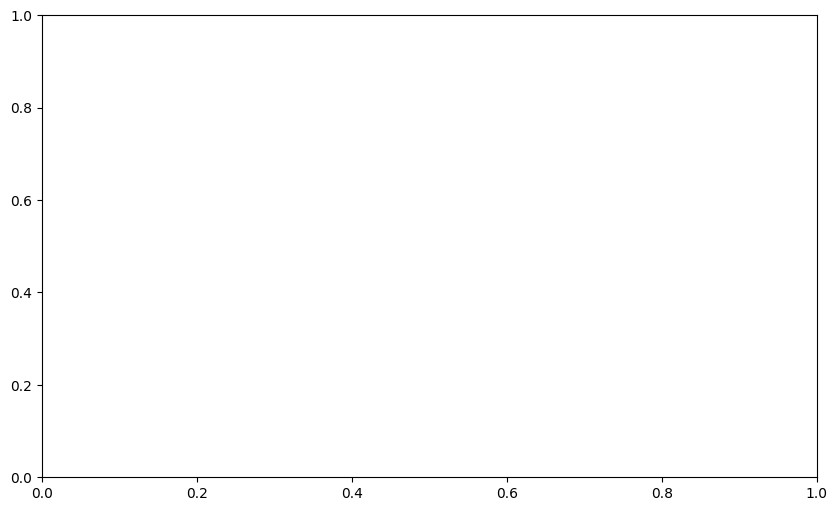

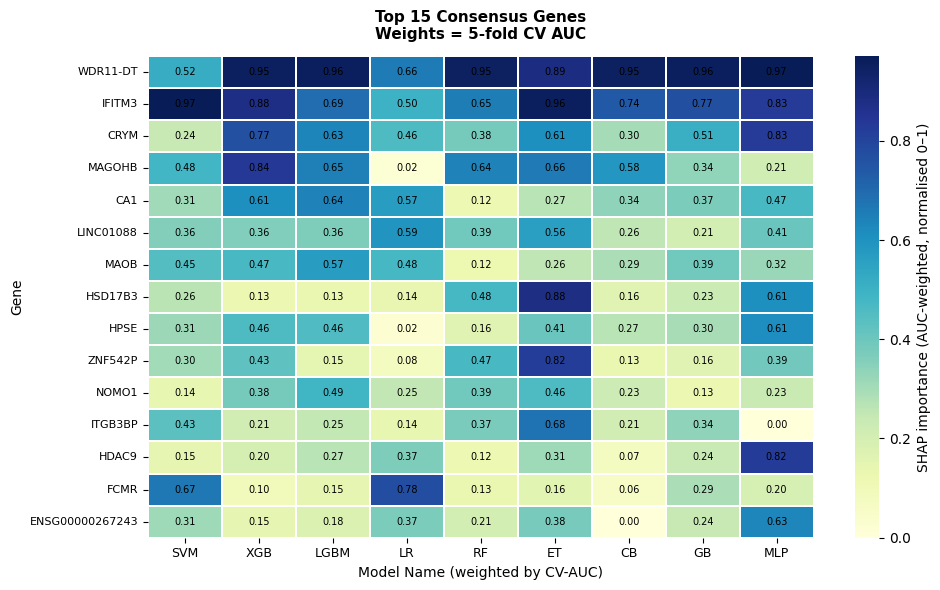

<Figure size 640x480 with 0 Axes>

21:35:36 [INFO] Heatmap saved.


NameError: name 'vote_count' is not defined

In [ ]:


# ── [I] Heatmap — plot consensus genes ─────────────────────────────────
fig, ax = plt.subplots(figsize=(10, max(6, 0.38 * len(df_plot))))
sns.heatmap(
    df_plot,
    cmap="YlGnBu",
    vmin=0,
    vmax=df_plot.values.max(),
    ax=ax,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7, "color": "black"},
    cbar_kws={"label": "SHAP importance (AUC-weighted, normalized 0–1)"},
    linewidths=0.3,
    linecolor="white",
)
ax.set_title(
    f"Performance-Weighted Gene Consensus (n={len(consensus_genes)} genes)\nWeights = 5-fold CV AUC",
    fontsize=11,
    fontweight="bold",
    pad=12,
)
ax.set_xlabel("Model Name (weighted by CV-AUC)", fontsize=10)
ax.set_ylabel("Gene", fontsize=10)
ax.tick_params(axis="x", rotation=0, labelsize=9)
ax.tick_params(axis="y", rotation=0, labelsize=8)
plt.tight_layout()
plt.savefig(os.path.join(CFG.out_dir, "shap_consensus_heatmap.png"), dpi=200, bbox_inches="tight")
plt.show()
log.info("Heatmap saved.")

# ── [J] Save consensus values & vote counts ────────────────────────────────
df_plot_save = df_plot.copy()
df_plot_save["vote_count"] = vote_count[df_plot.index]
df_plot_save["__total__"] = df_shap_weighted.loc[df_plot.index].sum(axis=1)
df_plot_save.to_csv(os.path.join(CFG.out_dir, "shap_consensus_values.csv"))
log.info(f"SHAP consensus values saved — {len(df_plot)} genes.")

In [ ]:

# ── [I] Heatmap ─────────────────────────────────────────────────────────────
# ── [I] Heatmap ─────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, max(6, 0.38 * len(df_plot))))

sns.heatmap(
    df_plot,
    cmap="YlGnBu",
    vmin=0,
    vmax=df_plot.values.max(),
    ax=ax,
    annot=True,                                        # ← show numbers
    fmt=".2f",                                         # ← 2 decimal places
    annot_kws={"size": 7, "color": "black"},           # ← font size in cells
    cbar_kws={"label": "SHAP importance (AUC-weighted, normalised 0–1)"},
    linewidths=0.3,
    linecolor="white",
)

ax.set_title(
    "Performance-Weighted Gene Consensus\n"
    "(Weights based on CV-AUC from 5-fold OOF)",
    fontsize=11, fontweight="bold", pad=12,
)
ax.set_xlabel("Model Name (weighted by CV-AUC)", fontsize=10)
ax.set_ylabel("Gene", fontsize=10)
ax.tick_params(axis="x", rotation=0, labelsize=9)
ax.tick_params(axis="y", rotation=0, labelsize=8)

plt.tight_layout()
plt.savefig(
    os.path.join(CFG.out_dir, "shap_consensus_heatmap.png"),
    dpi=200, bbox_inches="tight",
)
plt.show()
log.info("Heatmap saved.")


# ── [J] Save raw values ─────────────────────────────────────────────────────
df_shap_weighted.to_csv(
    os.path.join(CFG.out_dir, "shap_consensus_values.csv")
)
log.info("SHAP consensus values saved to CSV.")